# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import SARShipDetectionDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv

## Visualize images and objects witn bounding boxes

Total number of patches: 39729


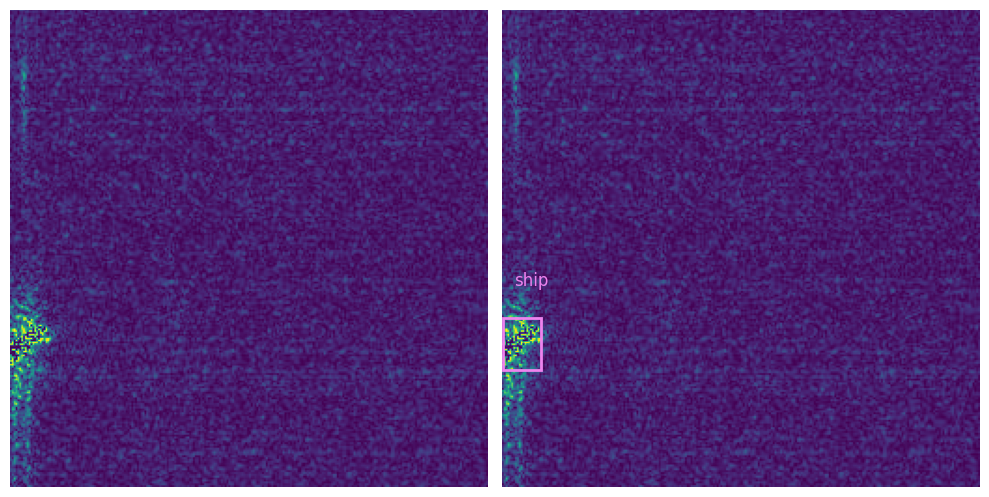

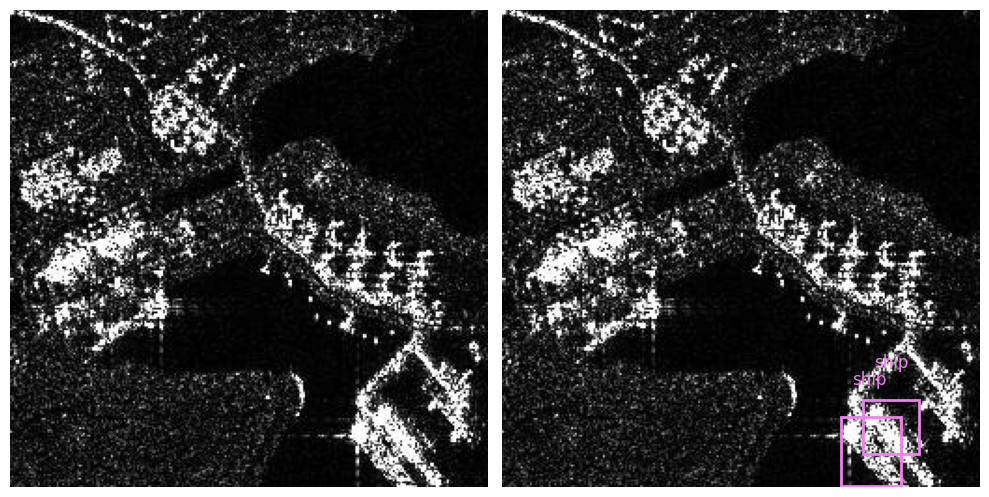

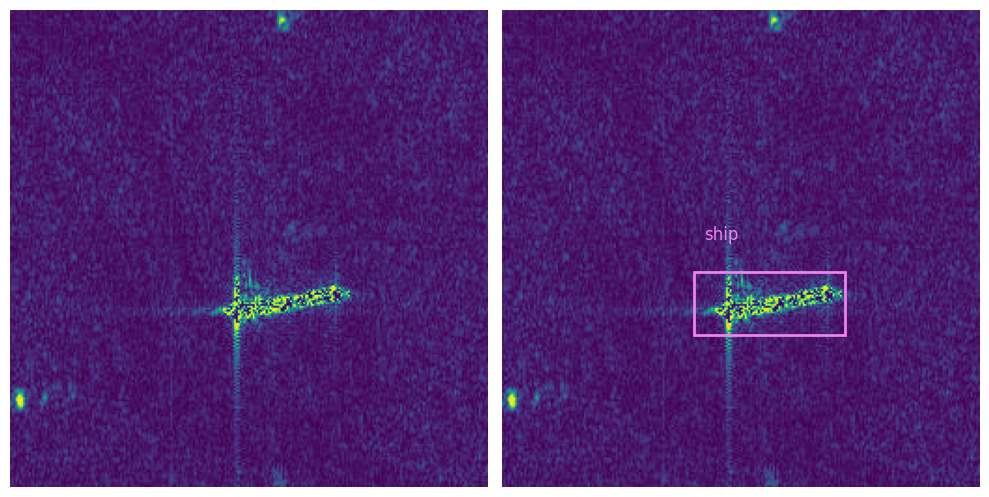

In [ ]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/SAR_ship_detection/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SAR_ship_detection/labels/",
}
dataset = SARShipDetectionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

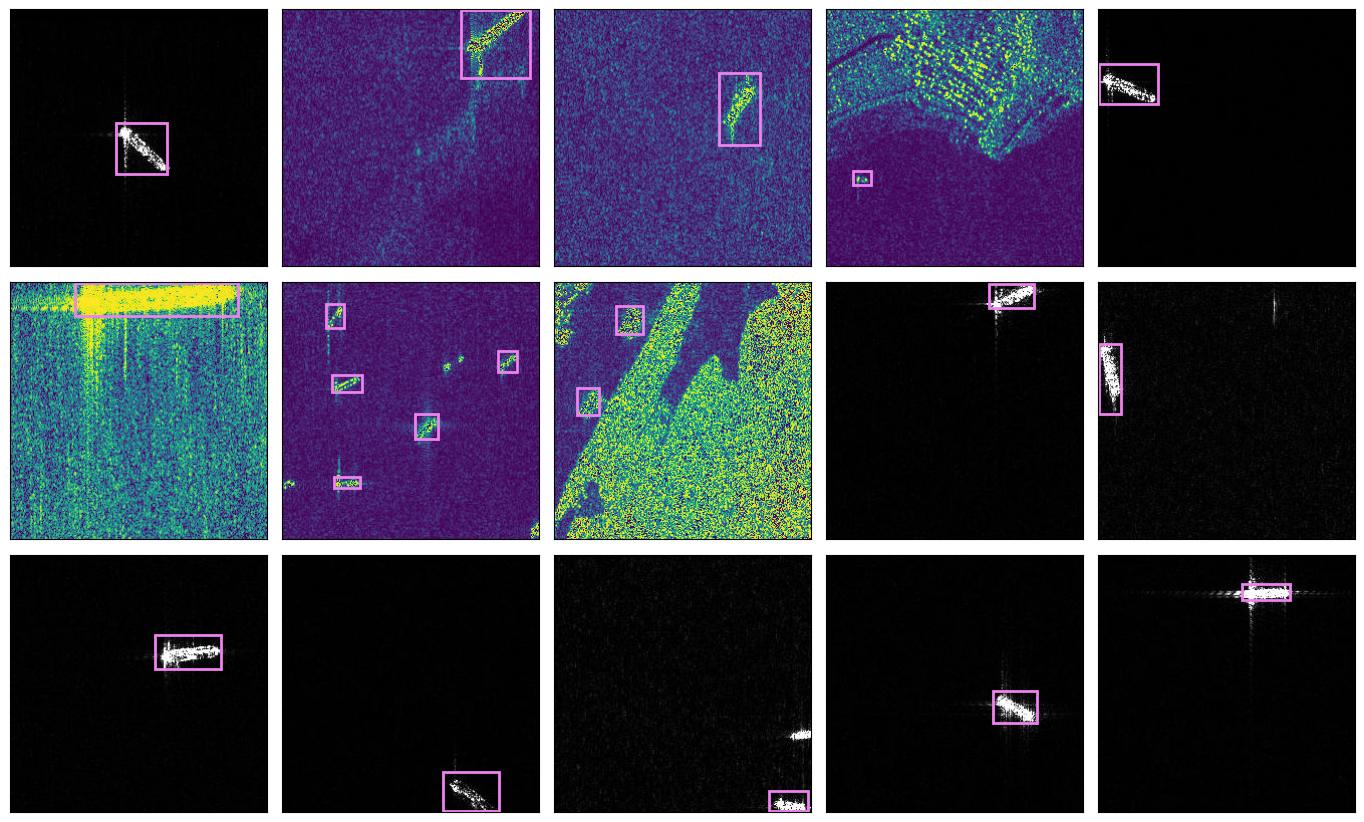

In [13]:
dataset.show_batch(15);

In [14]:
dataset.data_distribution_table()

,Label,Count
0,ship,50885


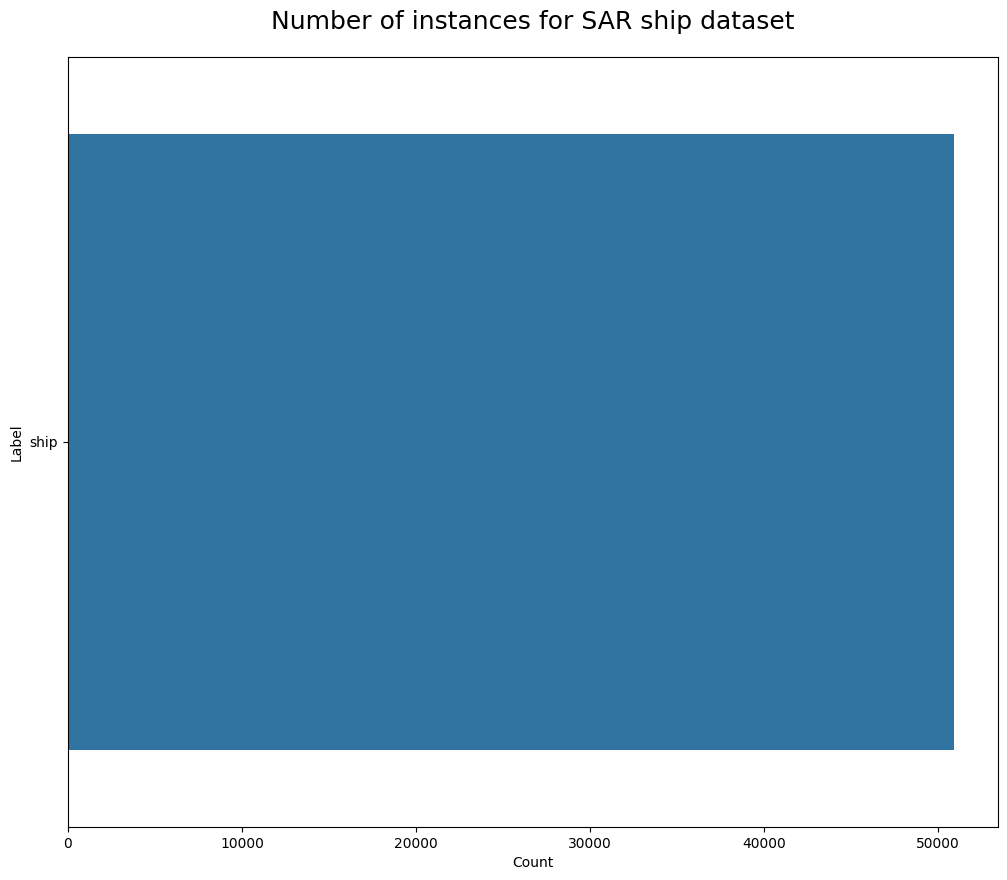

In [15]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/SAR_ship_detection/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SAR_ship_detection/labels/",
    "csv_file": "/home/dragik/data/FAIR_EO/SAR_ship_detection/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = SARShipDetectionDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 31784


## Create the model

In [7]:
epochs = 5
model_directory = "/home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [29]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-04-30 09:36:57,795 INFO Starting training.
training: 100%|██████████| 3973/3973 [21:30<00:00,  3.08it/s]
2025-04-30 09:58:28,157 INFO epoch: 1, time: 1291, loss:  0.12707
testing on train set: 100%|██████████| 3973/3973 [11:11<00:00,  5.91it/s]
2025-04-30 10:10:09,445 INFO map:0.5538544654846191, map_50:0.9378612637519836, map_75:0.605406641960144, map_small:0.44077983498573303, map_medium:0.5631464719772339, map_large:0.560609757900238, mar_1:0.4951952397823334, mar_10:0.6258059144020081, mar_100:0.6286495327949524, mar_small:0.5477339029312134, mar_medium:0.6384802460670471, mar_large:0.6181408166885376, map_per_class:0.5538544654846191, mar_100_per_class:0.6286495327949524, classes:1.0
training: 100%|██████████| 3973/3973 [21:28<00:00,  3.08it/s]
2025-04-30 10:31:37,590 INFO epoch: 2, time: 1288, loss:  0.10971
testing on train set: 100%|██████████| 3973/3973 [11:06<00:00,  5.96it/s]
2025-04-30 10:43:11,305 INFO map:0.5955830216407776, map_50:0.9567508101463318, map_75:0.684052

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/SAR_ship_detection/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SAR_ship_detection/labels/",
    "csv_file": "/home/dragik/data/FAIR_EO/SAR_ship_detection/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = SARShipDetectionDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 3973


2025-05-05 06:47:55,482 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/checkpoint.pth.tar
2025-05-05 06:47:56,083 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 497/497 [01:25<00:00,  5.84it/s]


[{'map': 0.6371549367904663,
  'map_50': 0.9601631164550781,
  'map_75': 0.7669796347618103,
  'map_small': 0.47070425748825073,
  'map_medium': 0.6471787691116333,
  'map_large': 0.6910351514816284,
  'mar_1': 0.5595706701278687,
  'mar_10': 0.6918107867240906,
  'mar_100': 0.6934207677841187,
  'mar_small': 0.5403712391853333,
  'mar_medium': 0.7049845457077026,
  'mar_large': 0.7379844784736633,
  'map_per_class': 0.6371549367904663,
  'mar_100_per_class': 0.6934207677841187,
  'classes': 1.0}]

## Predictions

2025-05-05 06:58:56,079 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/checkpoint.pth.tar
2025-05-05 06:58:56,501 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/checkpoint.pth.tar at epoch 6


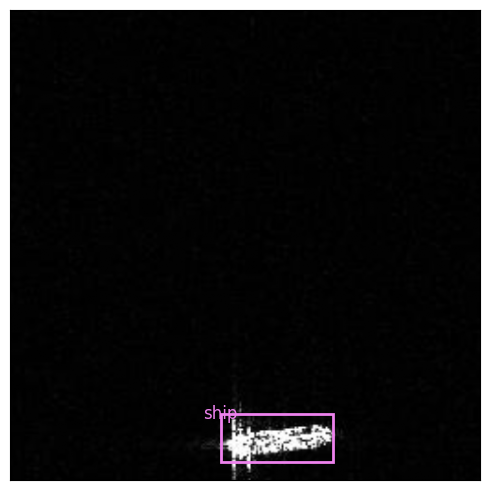

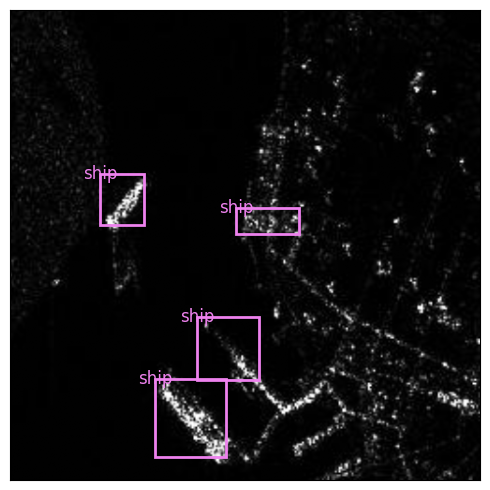

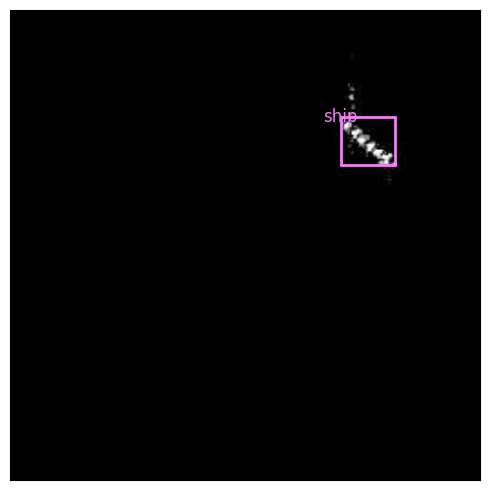

In [21]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/SAR_ship_detection/experiments/checkpoint.pth.tar"
labels = ["no-data","ship"]
transform = Resize()
model.load_model(model_path)

csv_file = "/home/dragik/data/FAIR_EO/SAR_ship_detection/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/SAR_ship_detection/' + test_list[1])  
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SAR_ship_detection/' + test_list[6])
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SAR_ship_detection/' + test_list[9])
fig = model.detect_objects(image, labels, transform)